# GridGuard — Dataset audit, EDA and split design

**Module 1**

This is an executable handoff, not a model-training notebook. It reproduces the audit and creates stable split manifests. LAB 4 emphasizes avoiding feature-selection leakage; LAB 5 requires data quality analysis and documented splits.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
from src.audit import read_inputs, make_groups, choose_splits, main
print("Repository root:", Path.cwd())

Repository root: /mnt/data/GridGuard_Mahij_Module


## 1. Inspect the source and target

The ZIP contains a README and the source indices for 19,000 records. The 1,000-row CSV has no supplied source-index mapping.

In [2]:
data, features, source_readme, metadata = read_inputs()
print("Rows, columns:", data.shape)
print("Numerical features:", len(features))
print("Class balance:")
display(data.blackout.value_counts().sort_index().rename_axis("blackout").to_frame("records"))
print("ZIP provenance note:")
print(source_readme)

Rows, columns: (20000, 228)
Numerical features: 224
Class balance:


,records
blackout,
0,15968
1,4032


ZIP provenance note:
Blackout_PowerGraph_19000.csv

Source: PowerGraph, https://figshare.com/articles/dataset/PowerGraph/22820534
Source archive: dataset_cascades.zip (Figshare file 50083479).
Subset: IEEE-24, originally 21,500 simulated scenarios.
This file contains 19,000 additional original scenario records. Source scenario indices do not overlap those used in Blackout_PowerGraph_1000.csv; that previous extraction was reconstructed and verified exactly before selection.
Original source records may have identical feature values; these existing repetitions are preserved. This is an additional dataset, not an independent held-out test set.
The 225-column schema is identical to the previously provided 1,000-row CSV.
As in that CSV, original MATLAB matrices are flattened into 224 named input columns. Numeric values use 10 significant digits.
Target blackout is 1 when source demand-not-served is greater than zero, otherwise 0. This matches the source binary labels. It does not imply a tot

## 2. Audit and plot

The audit checks missing values, input duplication, conflicting labels and overlap across extracts. It also builds figures and frozen manifests. Note that descriptive comparisons across classes are **not** a training-time feature selection.

In [3]:
metrics = main()
print("Exact repeated records:", metrics["repeated_records"])
print("Shared feature patterns across extracts:", metrics["shared_distinct_feature_vectors_between_extracts"])

{
  "rows": 20000,
  "columns_in_source": 225,
  "input_features": 224,
  "target_counts": {
    "0": 15968,
    "1": 4032
  },
  "positive_rate": 0.2016,
  "missing_cells": 0,
  "nonfinite_input_cells": 0,
  "constant_columns": [],
  "unique_feature_vectors": 18579,
  "repeated_records": 1421,
  "exact_duplicate_full_records": 1421,
  "conflicting_labels_for_identical_inputs": 0,
  "shared_distinct_feature_vectors_between_extracts": 152,
  "source_index_unique_in_19000": true,
  "source_index_available_in_1000": false,
  "split_choice_seed_offset": 88,
  "split": {
    "train": {
      "rows": 13993,
      "share": 0.69965,
      "positive_count": 2820,
      "positive_rate": 0.20153,
      "unique_feature_groups": 13005
    },
    "validation": {
      "rows": 3010,
      "share": 0.1505,
      "positive_count": 607,
      "positive_rate": 0.20166,
      "unique_feature_groups": 2787
    },
    "test": {
      "rows": 2997,
      "share": 0.14985,
      "positive_count": 605,
      "

## 3. Inspect the EDA figures

01_target_by_extract.png


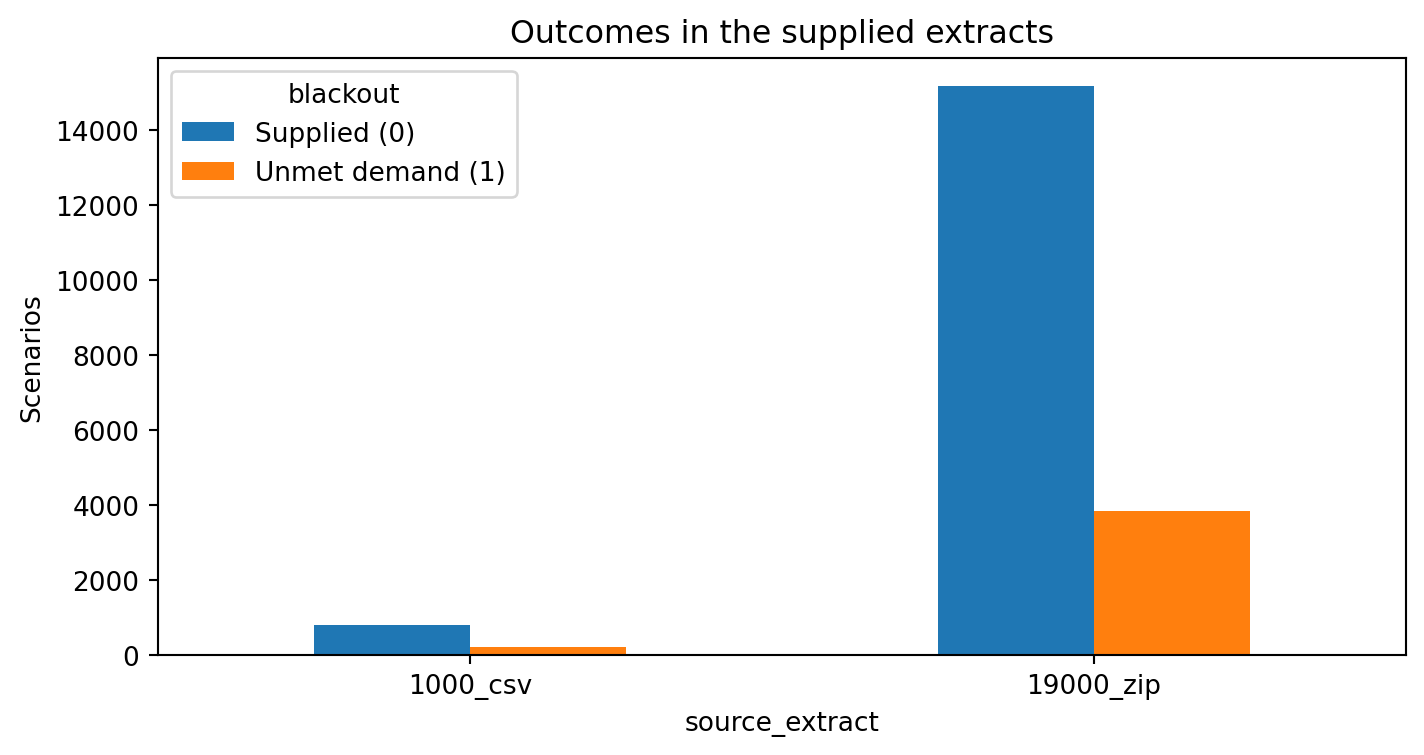

02_feature_families.png


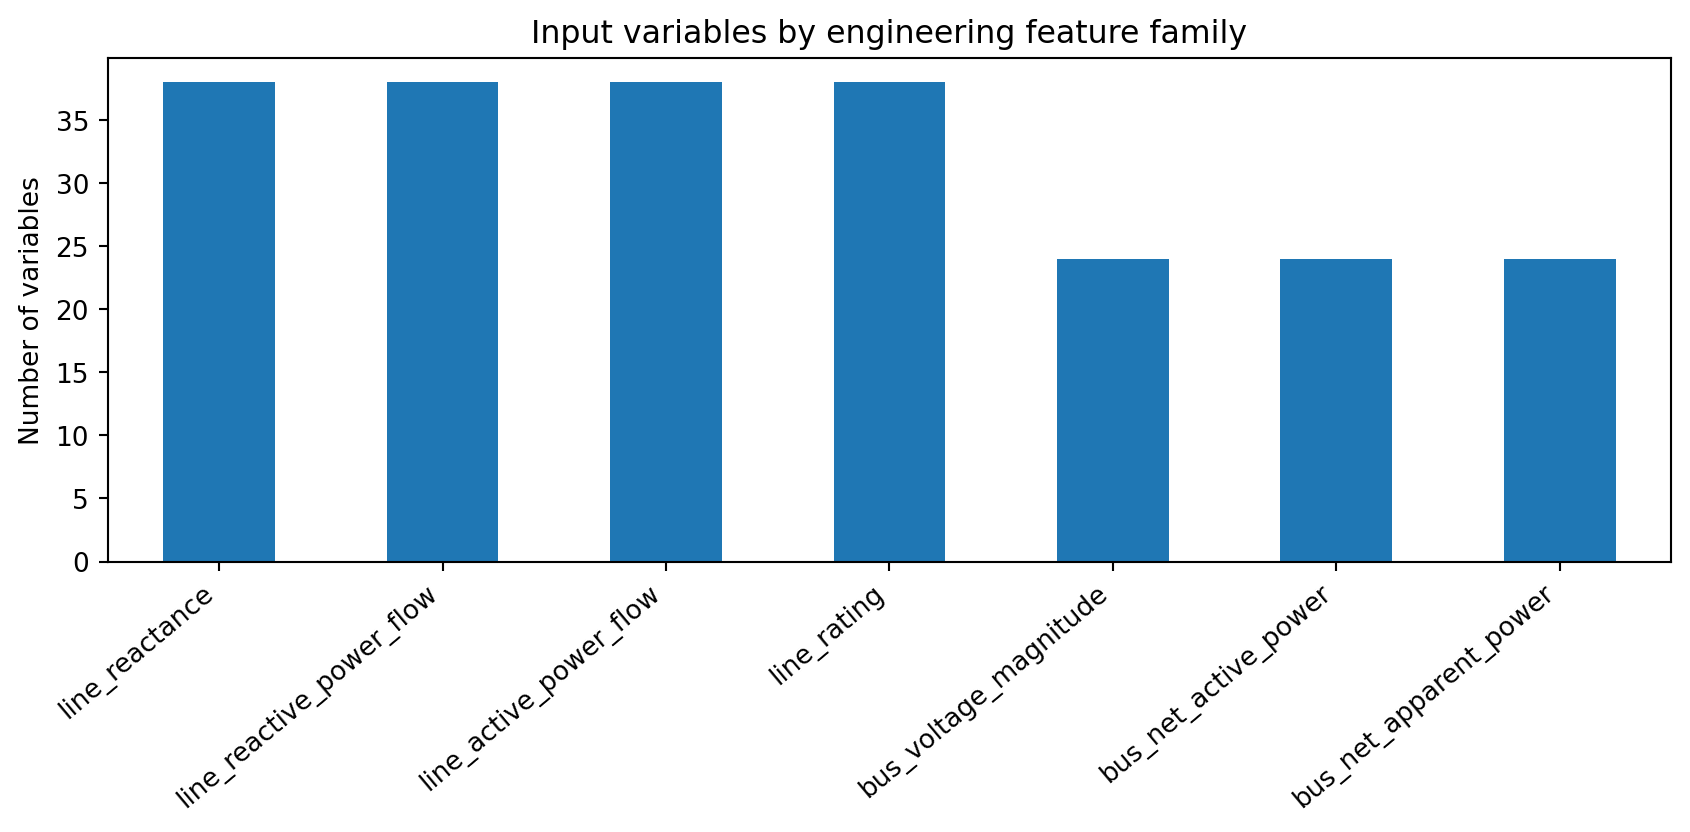

03_duplicate_group_sizes.png


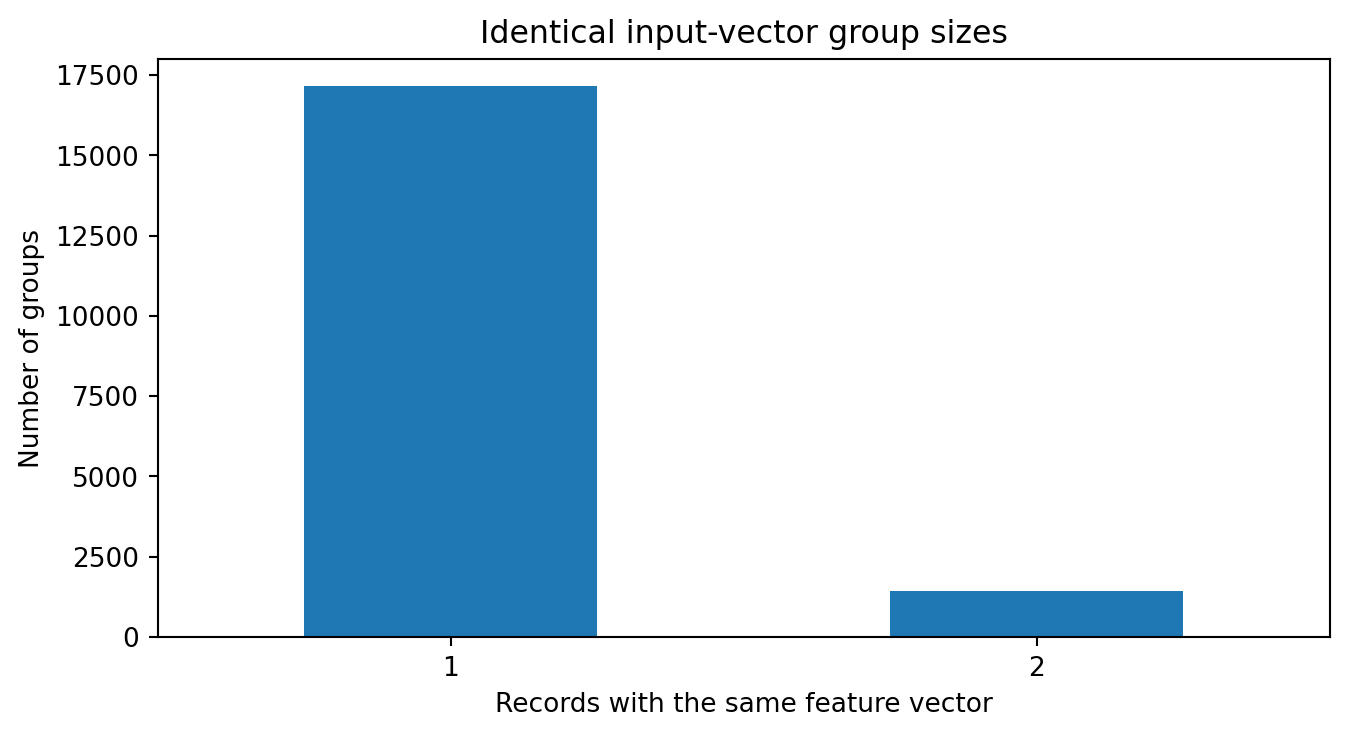

04_univariate_differences.png


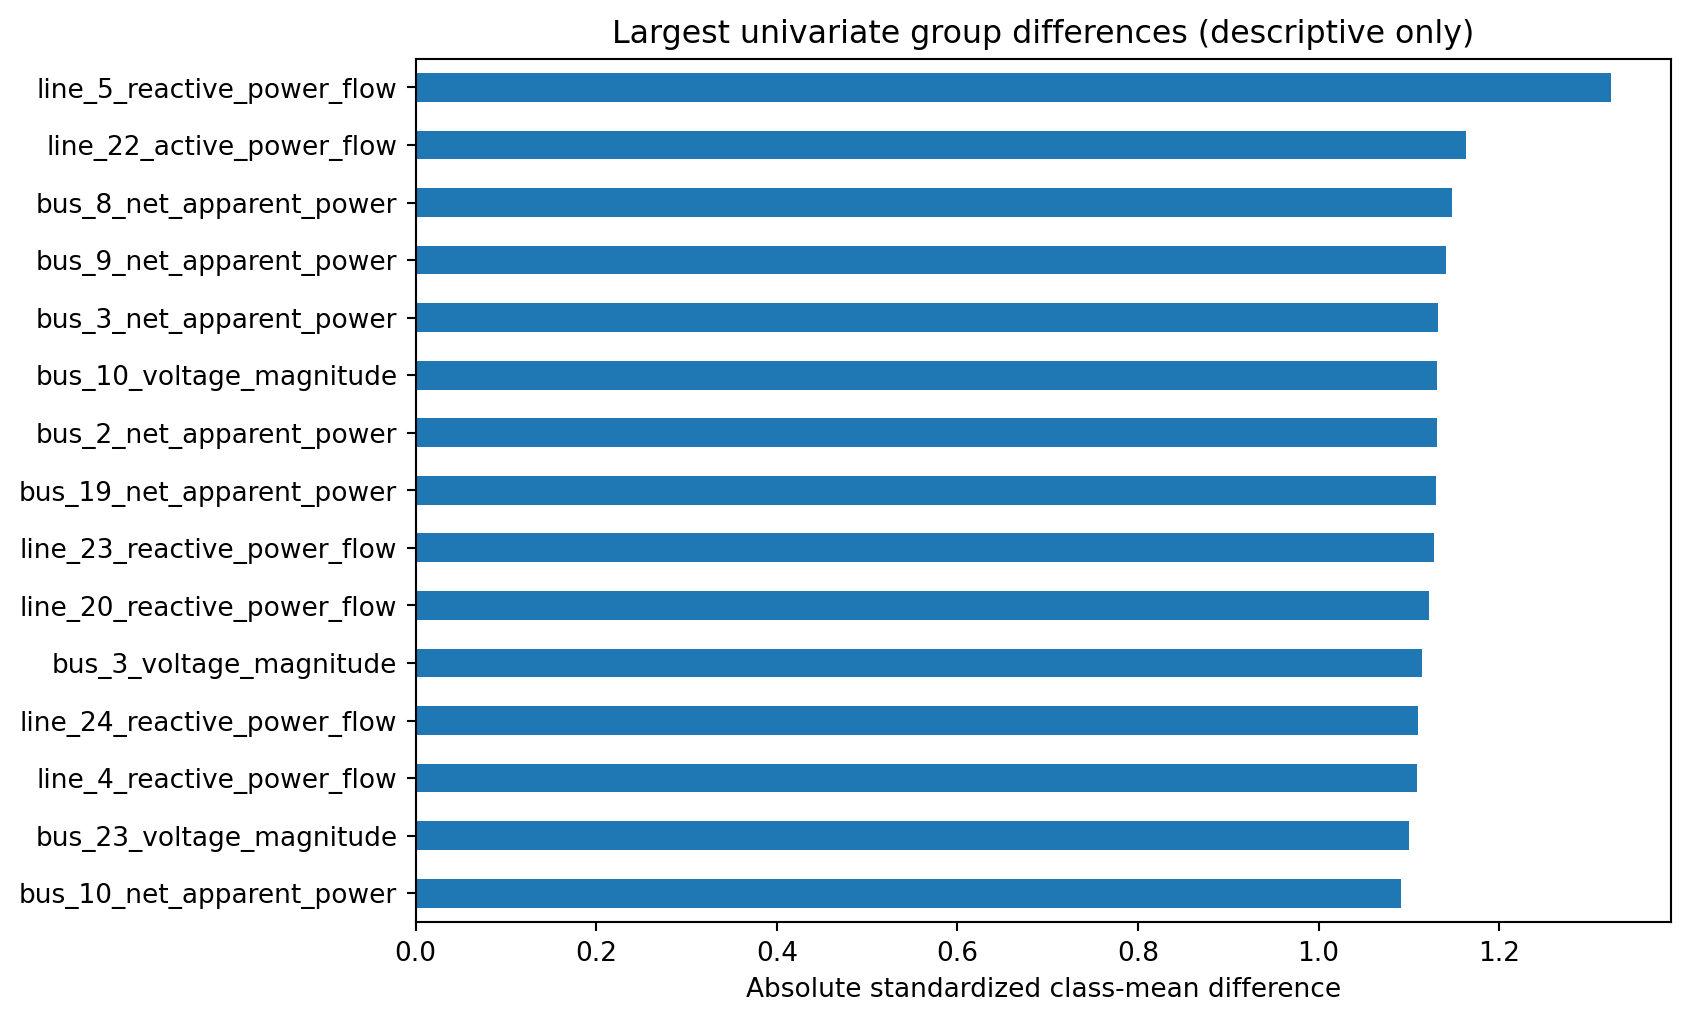

05_feature_correlations.png


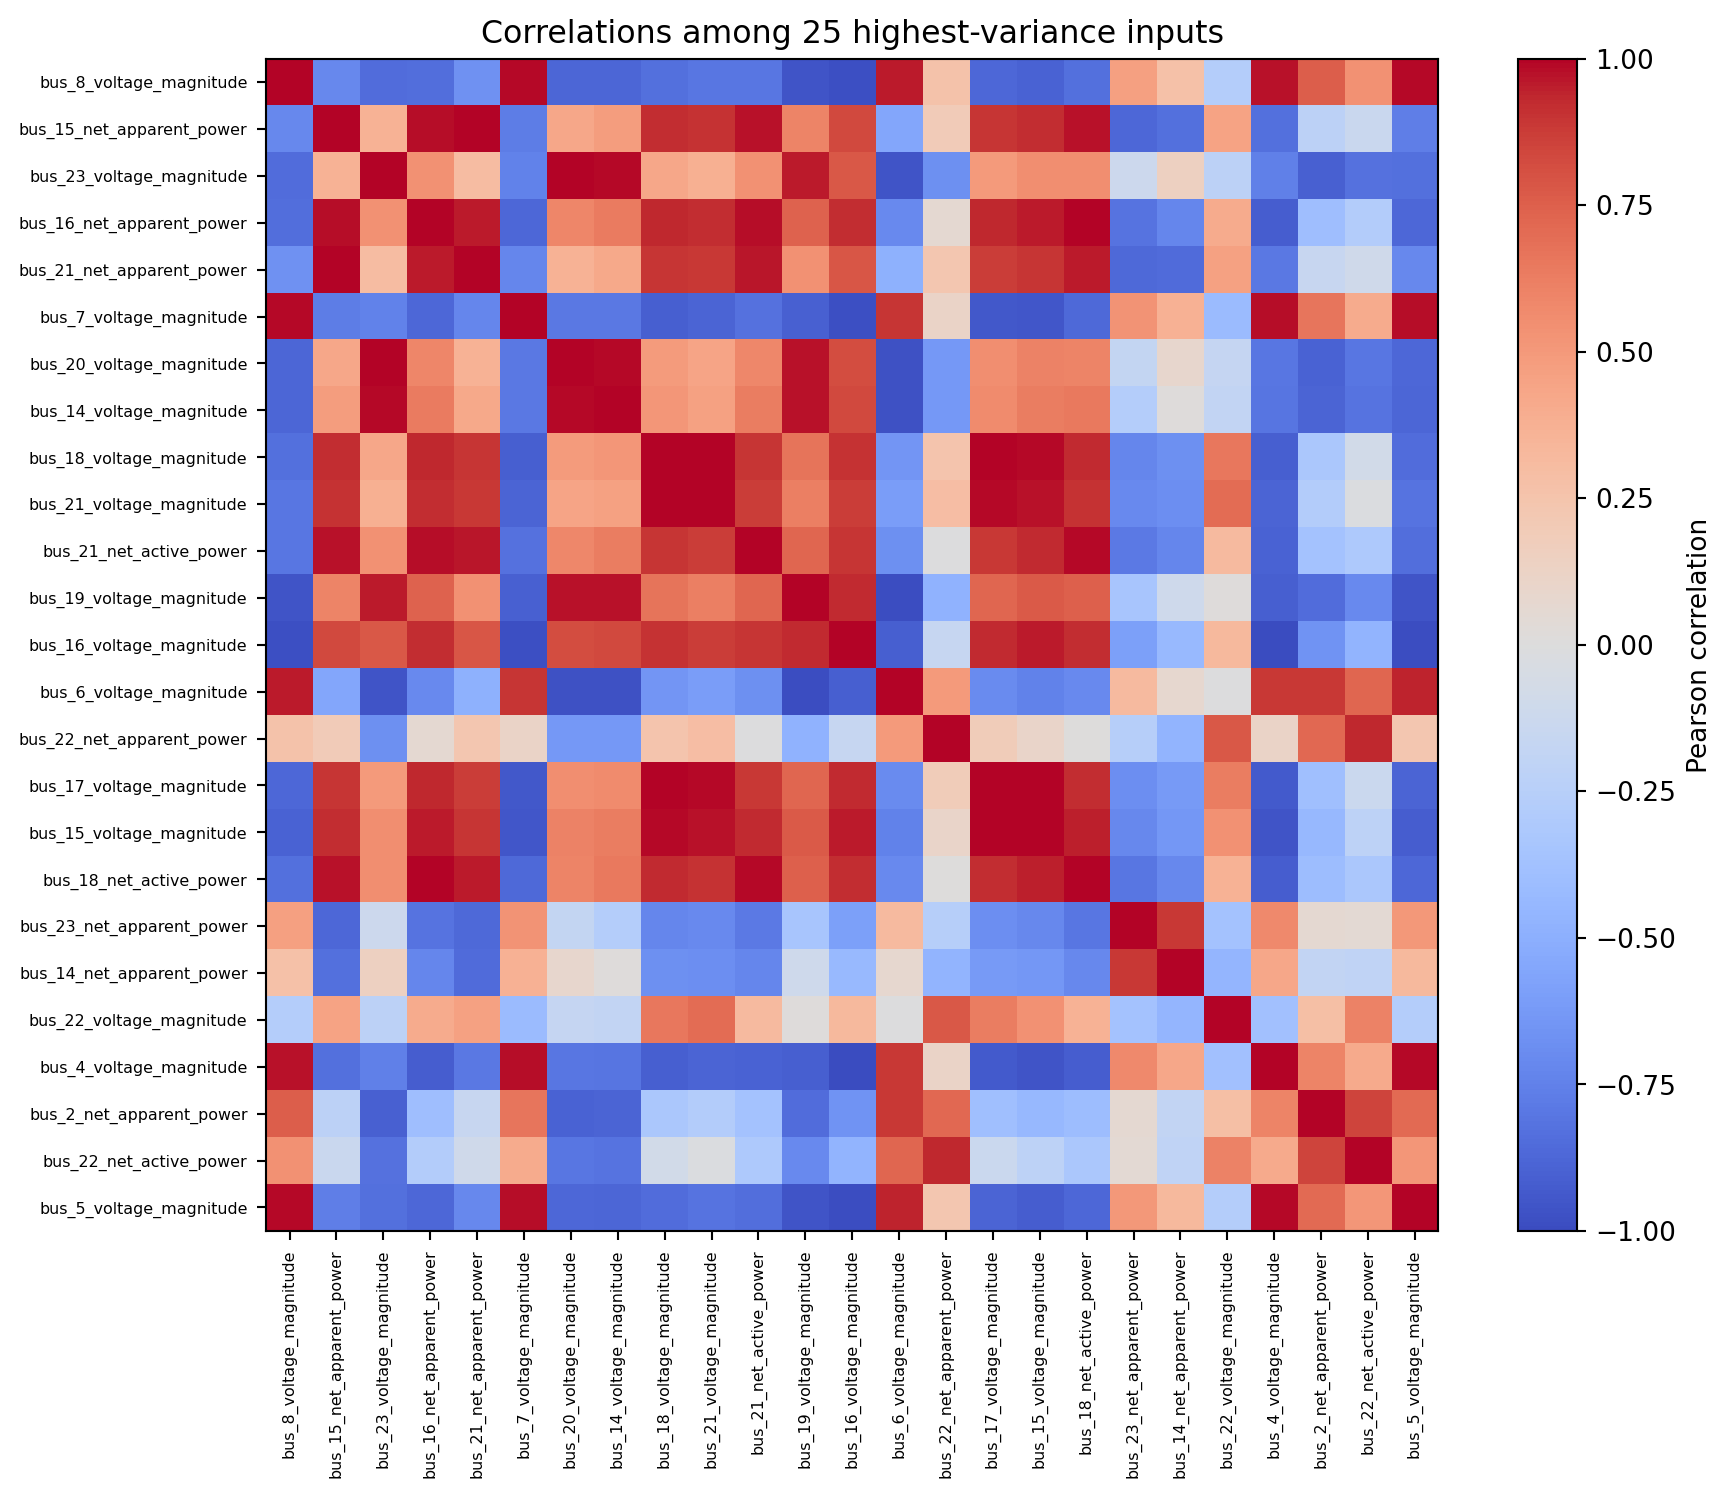

In [4]:
for file in sorted(Path("figures").glob("*.png")):
    print(file.name)
    display(Image(filename=str(file), width=650))

## 4. Train / test split (80/20, no validation CSV)

**Team instruction (Anais):** use the full 20,000-row dataset, save separate `train.csv` and `test.csv`, and ensure no identical input records are shared. We perform `train_test_split` **on unique input groups**, stratified by `blackout`; then assign every original record to its group's partition. This preserves all rows and prevents identical complete feature vectors from crossing into the test set. Exact 80/20 row counts are not guaranteed when groups have different sizes.

This split replaces the previous three-way split for **new experiments**. The earlier saved manifests are historical; models must be retrained before reporting results under these new partitions. Model selection and tuning can use cross-validation inside the training CSV.

In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

# Use ALL 20,000 rows. "blackout" is the label, not a feature.
df = pd.read_csv("data/processed/validated_20000.csv.gz")
X = df.drop(columns="blackout")
y = df["blackout"].astype(int)

# Same complete input values receive the same group ID.
# Group before splitting, so copies never leak into both datasets.
input_hashes = pd.util.hash_pandas_object(X, index=False)
group_ids, _ = pd.factorize(input_hashes, sort=False)
group_table = pd.DataFrame({"group": group_ids, "blackout": y})
assert group_table.groupby("group")["blackout"].nunique().max() == 1
unique_groups = group_table.drop_duplicates(subset="group")

# Stratified 80/20 split of UNIQUE groups; row counts are approximate.
train_groups, test_groups = train_test_split(
    unique_groups["group"], test_size=0.20,
    random_state=42, stratify=unique_groups["blackout"],
)
train_mask = np.isin(group_ids, train_groups)
test_mask = np.isin(group_ids, test_groups)
assert np.all(train_mask ^ test_mask)

# Two CSVs only: no separate validation dataset is needed.
train = df.loc[train_mask]
test = df.loc[test_mask]
assert set(input_hashes[train_mask]).isdisjoint(set(input_hashes[test_mask]))
print(f"Training: {len(train):,} records (blackout=1: {int(train.blackout.sum()):,})")
print(f"Testing:  {len(test):,} records (blackout=1: {int(test.blackout.sum()):,})")

# Check the actual committed files; avoid overwriting them in the notebook.
train_file = pd.read_csv("data/processed/train.csv")
test_file = pd.read_csv("data/processed/test.csv")
assert train_file.shape == train.shape and test_file.shape == test.shape
assert train_file.columns.equals(train.columns) and test_file.columns.equals(test.columns)
assert train_file["blackout"].sum() == train["blackout"].sum()
assert test_file["blackout"].sum() == test["blackout"].sum()
saved_train_hashes = set(pd.util.hash_pandas_object(train_file.drop(columns="blackout"), index=False))
saved_test_hashes = set(pd.util.hash_pandas_object(test_file.drop(columns="blackout"), index=False))
assert saved_train_hashes.isdisjoint(saved_test_hashes)
print("Verified train.csv and test.csv: zero identical input vectors shared.")


## 5. Handoff and leakage limitations

The two current files are **`data/processed/train.csv`** and **`data/processed/test.csv`**. Both contain all 224 original features and `blackout`; neither contains a validation set or a synthetic group-ID column. Teammates must not independently resplit the full dataset. Keep `test.csv` out of feature selection, hyperparameter tuning and threshold selection. Use cross-validation within `train.csv`.

**Verified guarantee:** no identical complete input vectors occur in both CSV files. **Remaining risks:** distinct input vectors can still come from related simulated operating conditions; the source does not establish that all input measurements were available before the simulated disruption. Do not equate exact-duplicate isolation with proof of full scenario independence.